In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn plotly

In [2]:

import pandas as pd
import numpy as np


import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans


pd.set_option('display.max_columns', None)

print("All libraries imported successfully!")

All libraries imported successfully!


In [10]:
df = pd.read_csv("dataset.csv")
df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [13]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 114000
Number of Columns: 21


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          11

In [15]:
df.describe()

,Unnamed: 0,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,114000.000000,114000.000000,1.140000e+05,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000
mean,56999.500000,33.238535,2.280292e+05,0.566800,0.641383,5.309140,-8.258960,0.637553,0.084652,0.314910,0.156050,0.213553,0.474068,122.147837,3.904035
std,32909.109681,22.305078,1.072977e+05,0.173542,0.251529,3.559987,5.029337,0.480709,0.105732,0.332523,0.309555,0.190378,0.259261,29.978197,0.432621
min,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,28499.750000,17.000000,1.740660e+05,0.456000,0.472000,2.000000,-10.013000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.218750,4.000000
50%,56999.500000,35.000000,2.129060e+05,0.580000,0.685000,5.000000,-7.004000,1.000000,0.048900,0.169000,0.000042,0.132000,0.464000,122.017000,4.000000
75%,85499.250000,50.000000,2.615060e+05,0.695000,0.854000,8.000000,-5.003000,1.000000,0.084500,0.598000,0.049000,0.273000,0.683000,140.071000,4.000000
max,113999.000000,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


In [16]:
df.isnull().sum()

Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

In [17]:
df.columns.tolist()

['Unnamed: 0',
 'track_id',
 'artists',
 'album_name',
 'track_name',
 'popularity',
 'duration_ms',
 'explicit',
 'danceability',
 'energy',
 'key',
 'loudness',
 'mode',
 'speechiness',
 'acousticness',
 'instrumentalness',
 'liveness',
 'valence',
 'tempo',
 'time_signature',
 'track_genre']

In [19]:
numerical_columns = df.select_dtypes(
    include=['int64', 'float64']
).columns

print("Numerical Columns:")
print(numerical_columns.tolist())


Numerical Columns:
['Unnamed: 0', 'popularity', 'duration_ms', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature']


In [20]:
categorical_columns = df.select_dtypes(
    include=['object']
).columns

print("\nCategorical Columns:")
print(categorical_columns.tolist())


Categorical Columns:
['track_id', 'artists', 'album_name', 'track_name', 'track_genre']


In [21]:
missing_values = df.isnull().sum()

missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

missing_df = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': missing_percentage
})

missing_df.sort_values(
    by='Missing Percentage',
    ascending=False
)

,Missing Values,Missing Percentage
artists,1,0.000877
album_name,1,0.000877
track_name,1,0.000877
Unnamed: 0,0,0.000000
mode,0,0.000000
time_signature,0,0.000000
tempo,0,0.000000
valence,0,0.000000
liveness,0,0.000000
instrumentalness,0,0.000000


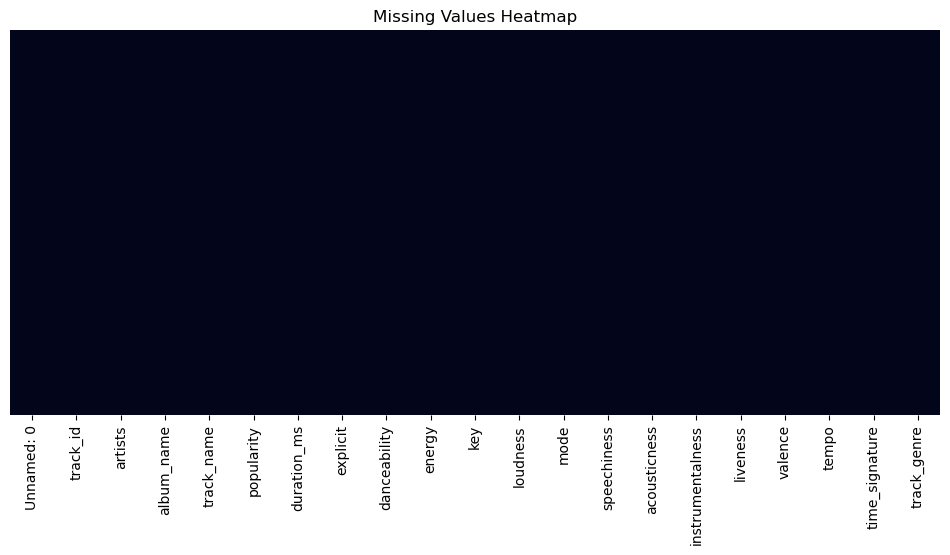

In [22]:
plt.figure(figsize=(12, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing Values Heatmap")
plt.show()

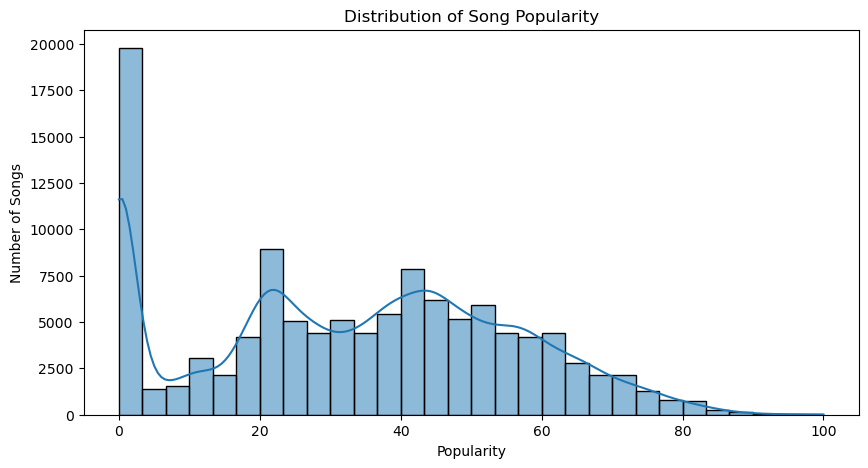

In [23]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['popularity'],
    bins=30,
    kde=True
)

plt.title("Distribution of Song Popularity")
plt.xlabel("Popularity")
plt.ylabel("Number of Songs")

plt.show()

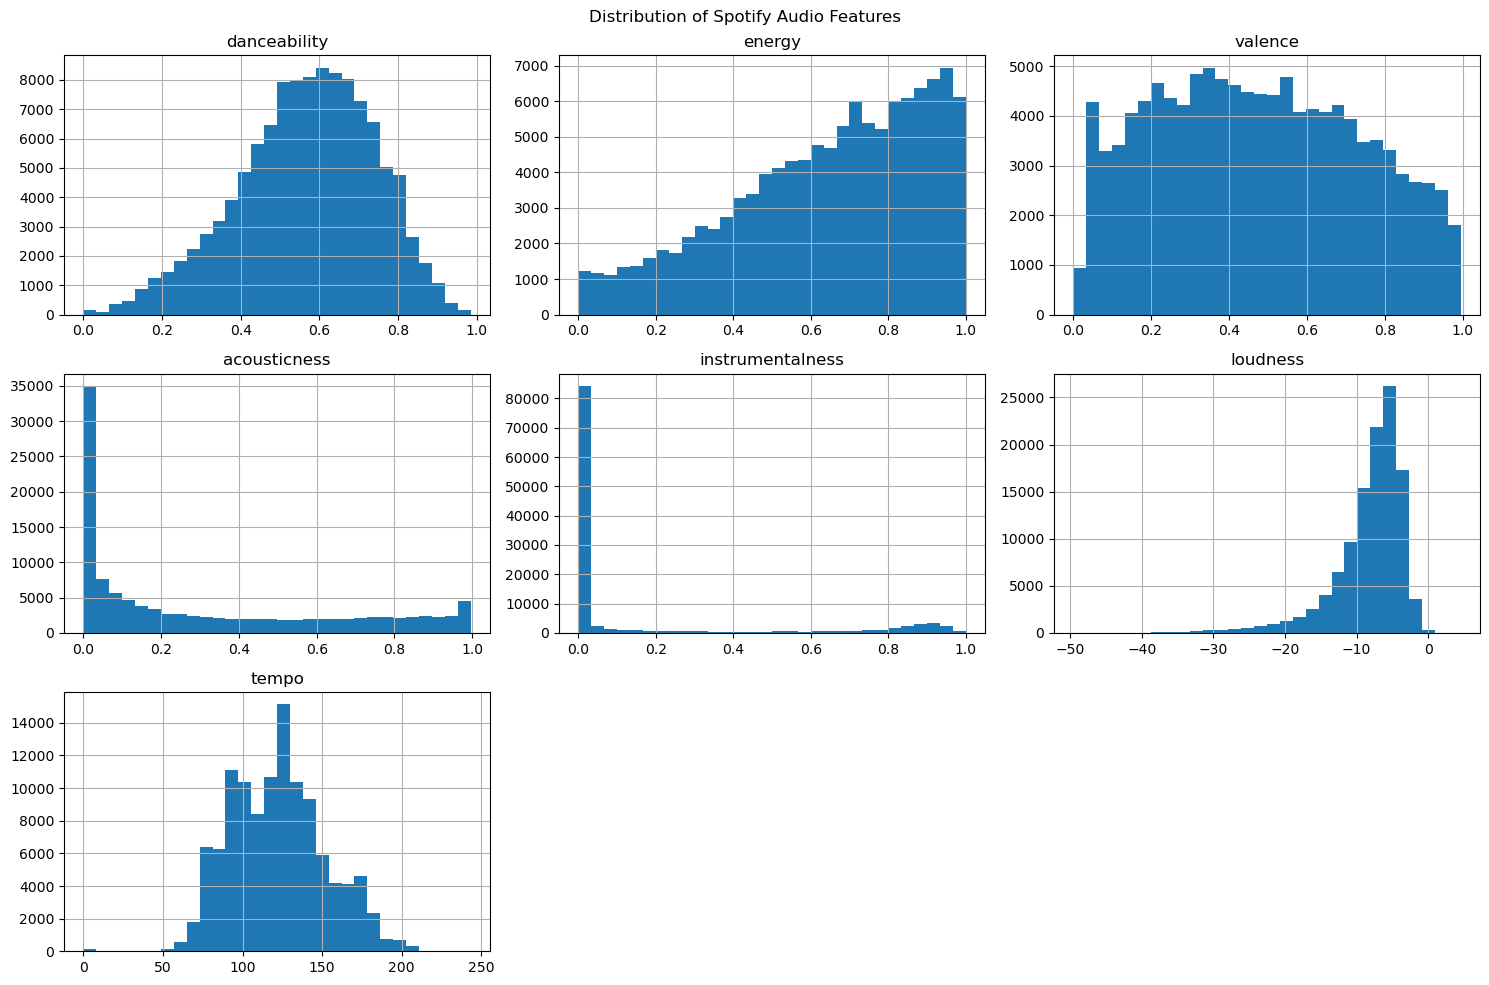

In [24]:
audio_features = [
    'danceability',
    'energy',
    'valence',
    'acousticness',
    'instrumentalness',
    'loudness',
    'tempo'
]

df[audio_features].hist(
    figsize=(15, 10),
    bins=30
)

plt.suptitle("Distribution of Spotify Audio Features")

plt.tight_layout()
plt.show()

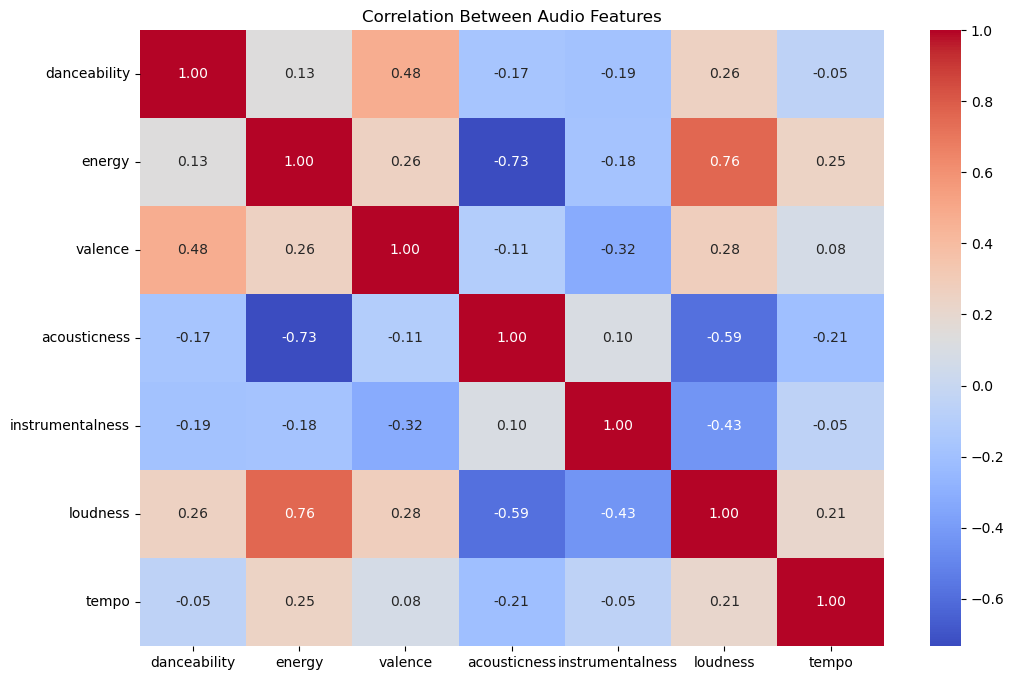

In [25]:
correlation = df[audio_features].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Between Audio Features")

plt.show()

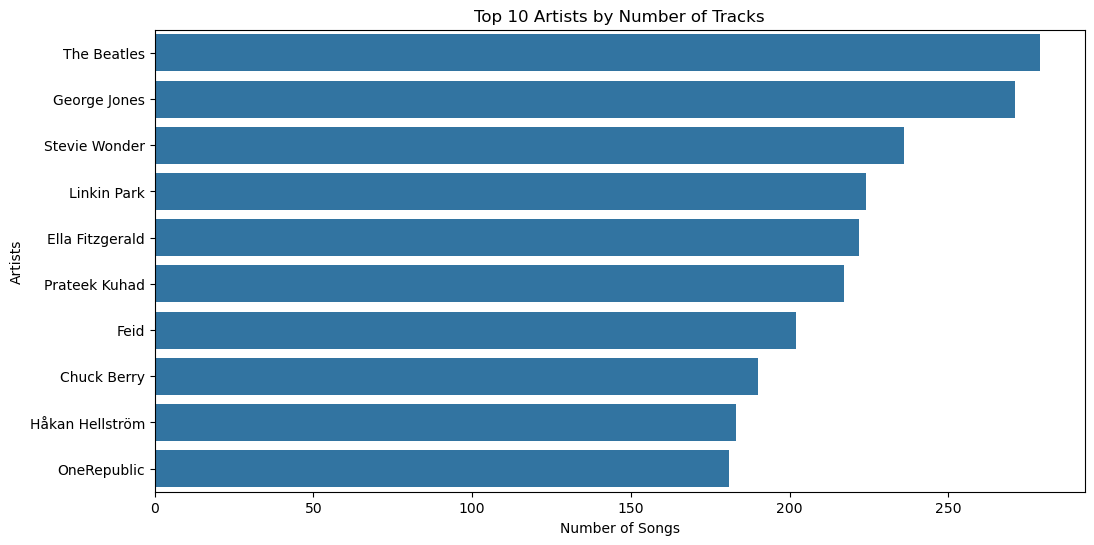

In [26]:
top_artists = (
    df['artists']
    .value_counts()
    .head(10)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_artists.values,
    y=top_artists.index
)

plt.title("Top 10 Artists by Number of Tracks")
plt.xlabel("Number of Songs")
plt.ylabel("Artists")

plt.show()

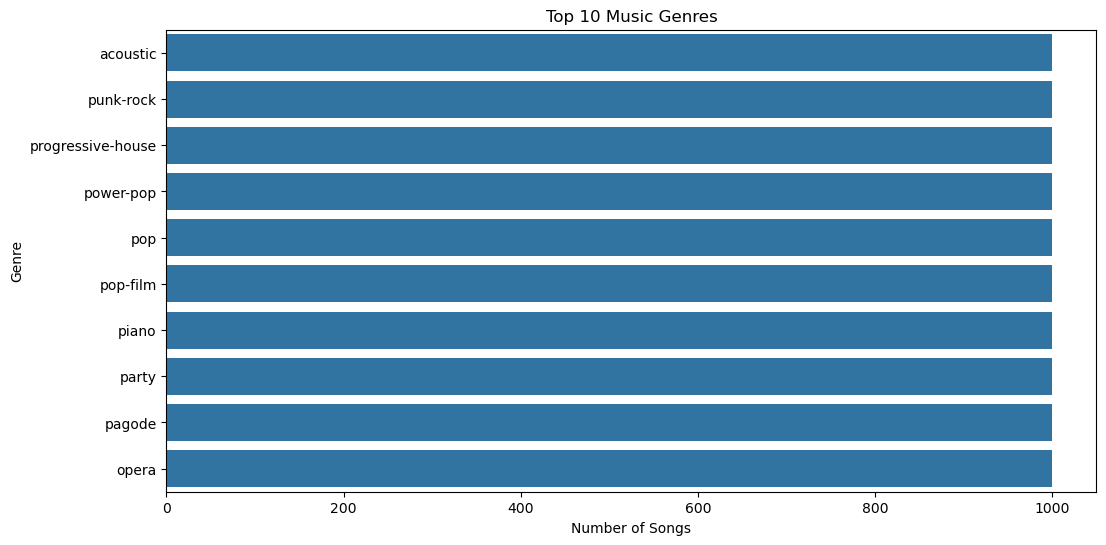

In [27]:
top_genres = df['track_genre'].value_counts().head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_genres.values,
    y=top_genres.index
)

plt.title("Top 10 Music Genres")
plt.xlabel("Number of Songs")
plt.ylabel("Genre")

plt.show()

In [28]:
print("Before Cleaning:", df.shape)

Before Cleaning: (114000, 21)


In [29]:
missing = df.isnull().sum()

print(missing[missing > 0])

artists       1
album_name    1
track_name    1
dtype: int64


In [30]:
required_columns = [
    'track_name',
    'artists',
    'danceability',
    'energy',
    'valence',
    'acousticness',
    'instrumentalness',
    'tempo',
    'loudness'
]

df = df.dropna(subset=required_columns)

print("After Missing Value Treatment:", df.shape)

After Missing Value Treatment: (113999, 21)


In [31]:
print("Duplicates:", df.duplicated().sum())

Duplicates: 0


In [32]:
df = df.drop_duplicates()

print("After removing duplicates:", df.shape)

After removing duplicates: (113999, 21)


In [33]:
print(
    "Duplicate Song Records:",
    df.duplicated(subset=['track_name', 'artists']).sum()
)

Duplicate Song Records: 32656


In [34]:
df.duplicated(subset=['track_name', 'artists']).sum()

np.int64(32656)

In [35]:
duplicate_songs = df[
    df.duplicated(
        subset=['track_name', 'artists'],
        keep=False
    )
]

display(
    duplicate_songs[
        ['track_name', 'artists', 'track_genre',
         'popularity', 'danceability', 'energy']
    ].head(20)
)

,track_name,artists,track_genre,popularity,danceability,energy
0,Comedy,Gen Hoshino,acoustic,73,0.676,0.4610
1,Ghost - Acoustic,Ben Woodward,acoustic,55,0.420,0.1660
3,Can't Help Falling In Love,Kina Grannis,acoustic,71,0.266,0.0596
4,Hold On,Chord Overstreet,acoustic,82,0.618,0.4430
5,Days I Will Remember,Tyrone Wells,acoustic,58,0.688,0.4810
6,Say Something,A Great Big World;Christina Aguilera,acoustic,74,0.407,0.1470
7,I'm Yours,Jason Mraz,acoustic,80,0.703,0.4440
8,Lucky,Jason Mraz;Colbie Caillat,acoustic,74,0.625,0.4140
9,Hunger,Ross Copperman,acoustic,56,0.442,0.6320
10,Give Me Your Forever,Zack Tabudlo,acoustic,74,0.627,0.3630


In [36]:
print("Total Records:", len(df))

print(
    "Unique Song-Artist Combinations:",
    df[['track_name', 'artists']].drop_duplicates().shape[0]
)

print(
    "Duplicate Song Records:",
    df.duplicated(
        subset=['track_name', 'artists']
    ).sum()
)

Total Records: 113999
Unique Song-Artist Combinations: 81343
Duplicate Song Records: 32656


In [37]:
print("Unique Track IDs:", df['track_id'].nunique())

print("Duplicate Track IDs:", df['track_id'].duplicated().sum())

Unique Track IDs: 89740
Duplicate Track IDs: 24259


In [38]:
duplicate_ids = df[
    df.duplicated(subset=['track_id'], keep=False)
]

display(
    duplicate_ids[
        ['track_id', 'track_name', 'artists',
         'track_genre', 'popularity']
    ].head(20)
)

,track_id,track_name,artists,track_genre,popularity
0,5SuOikwiRyPMVoIQDJUgSV,Comedy,Gen Hoshino,acoustic,73
1,4qPNDBW1i3p13qLCt0Ki3A,Ghost - Acoustic,Ben Woodward,acoustic,55
5,01MVOl9KtVTNfFiBU9I7dc,Days I Will Remember,Tyrone Wells,acoustic,58
6,6Vc5wAMmXdKIAM7WUoEb7N,Say Something,A Great Big World;Christina Aguilera,acoustic,74
7,1EzrEOXmMH3G43AXT1y7pA,I'm Yours,Jason Mraz,acoustic,80
9,7k9GuJYLp2AzqokyEdwEw2,Hunger,Ross Copperman,acoustic,56
12,4ptDJbJl35d7gQfeNteBwp,Solo,Dan Berk,acoustic,52
13,0X9MxHR1rTkEHDjp95F2OO,Bad Liar,Anna Hamilton,acoustic,62
16,6xKeQgzfjixSUld14qUezm,ily (i love you baby),Andrew Foy;Renee Foy,acoustic,56
17,4Yo0igmcoNyat1secaH0OD,At My Worst,Andrew Foy;Renee Foy,acoustic,54


In [39]:
duplicate_genres = (
    duplicate_ids.groupby('track_id')['track_genre']
    .nunique()
)

print("Track IDs with multiple genres:",
      (duplicate_genres > 1).sum())

Track IDs with multiple genres: 16299


In [40]:
print("Exact duplicate rows:", df.duplicated().sum())

print("Duplicate track IDs:",
      df.duplicated(subset=['track_id']).sum())

Exact duplicate rows: 0
Duplicate track IDs: 24259


In [41]:
df_clean = df.drop_duplicates(
    subset=['track_id'],
    keep='first'
).copy()

print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)
print("Remaining duplicate IDs:",
      df_clean['track_id'].duplicated().sum())

Original dataset: (113999, 21)
Cleaned dataset: (89740, 21)
Remaining duplicate IDs: 0


In [42]:
print("Track IDs with multiple genres:",
      (duplicate_ids.groupby('track_id')['track_genre']
       .nunique() > 1).sum())

Track IDs with multiple genres: 16299


In [43]:
print("Current dataset shape:", df_clean.shape)

print("Missing values:")
print(df_clean.isnull().sum())

print("Duplicate Track IDs:",
      df_clean['track_id'].duplicated().sum())

Current dataset shape: (89740, 21)
Missing values:
Unnamed: 0          0
track_id            0
artists             0
album_name          0
track_name          0
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64
Duplicate Track IDs: 0


In [44]:
audio_features = [
    'danceability',
    'energy',
    'valence',
    'acousticness',
    'instrumentalness',
    'tempo',
    'loudness'
]

X = df_clean[audio_features].copy()

print("Feature Matrix Shape:", X.shape)

display(X.head())

Feature Matrix Shape: (89740, 7)


,danceability,energy,valence,acousticness,instrumentalness,tempo,loudness
0,0.676,0.4610,0.715,0.0322,0.000001,87.917,-6.746
1,0.420,0.1660,0.267,0.9240,0.000006,77.489,-17.235
2,0.438,0.3590,0.120,0.2100,0.000000,76.332,-9.734
3,0.266,0.0596,0.143,0.9050,0.000071,181.740,-18.515
4,0.618,0.4430,0.167,0.4690,0.000000,119.949,-9.681


In [45]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Original Features:")
display(X.head())

print("Scaled Features:")
display(pd.DataFrame(
    X_scaled,
    columns=audio_features
).head())

Original Features:


,danceability,energy,valence,acousticness,instrumentalness,tempo,loudness
0,0.676,0.4610,0.715,0.0322,0.000001,87.917,-6.746
1,0.420,0.1660,0.267,0.9240,0.000006,77.489,-17.235
2,0.438,0.3590,0.120,0.2100,0.000000,76.332,-9.734
3,0.266,0.0596,0.143,0.9050,0.000071,181.740,-18.515
4,0.618,0.4430,0.167,0.4690,0.000000,119.949,-9.681


Scaled Features:


,danceability,energy,valence,acousticness,instrumentalness,tempo,loudness
0,0.644253,-0.675975,0.934047,-0.875166,-0.535482,-1.133599,0.335727
1,-0.804604,-1.825602,-0.770269,1.760810,-0.535468,-1.479843,-1.673087
2,-0.702731,-1.073473,-1.329497,-0.349626,-0.535485,-1.518259,-0.236524
3,-1.676182,-2.240247,-1.241999,1.704650,-0.535266,1.981635,-1.918228
4,0.315996,-0.746122,-1.150696,0.415925,-0.535485,-0.070030,-0.226373


In [46]:
scaled_df = pd.DataFrame(
    X_scaled,
    columns=audio_features
)

print("Feature Means:")
print(scaled_df.mean().round(2))

print("\nFeature Standard Deviations:")
print(scaled_df.std().round(2))

Feature Means:
danceability       -0.0
energy             -0.0
valence            -0.0
acousticness       -0.0
instrumentalness    0.0
tempo              -0.0
loudness           -0.0
dtype: float64

Feature Standard Deviations:
danceability        1.0
energy              1.0
valence             1.0
acousticness        1.0
instrumentalness    1.0
tempo               1.0
loudness            1.0
dtype: float64


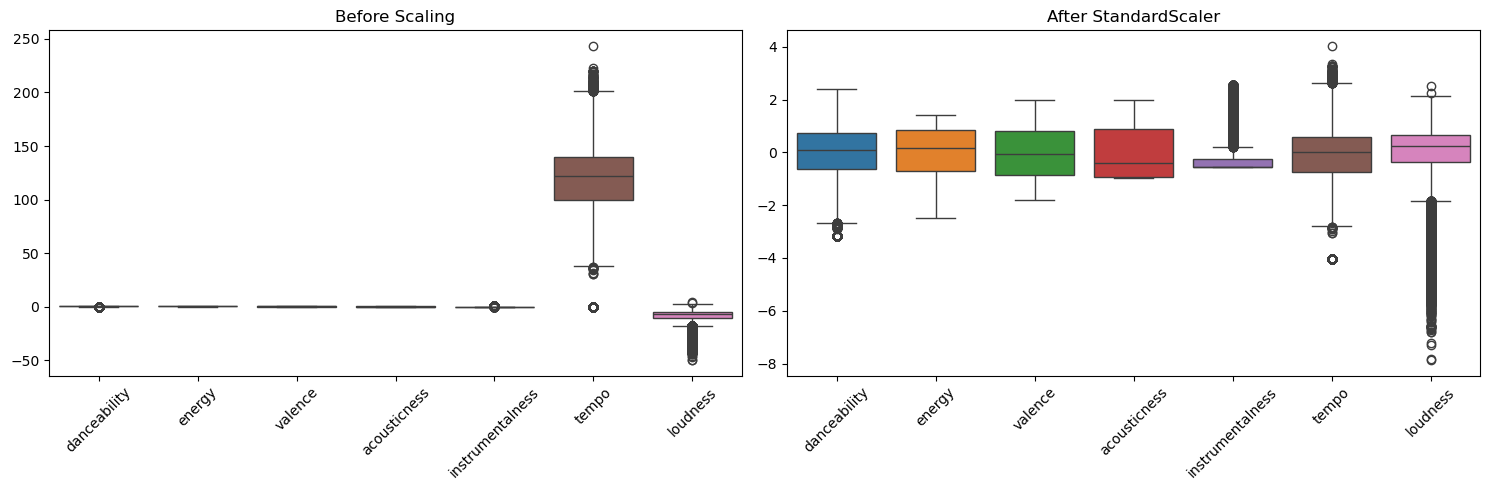

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(data=X, ax=axes[0])
axes[0].set_title("Before Scaling")
axes[0].tick_params(axis='x', rotation=45)

sns.boxplot(data=scaled_df, ax=axes[1])
axes[1].set_title("After StandardScaler")
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [48]:
from sklearn.preprocessing import StandardScaler

audio_features = [
    'danceability',
    'energy',
    'valence',
    'acousticness',
    'instrumentalness',
    'tempo',
    'loudness'
]

X = df_clean[audio_features].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Feature Matrix:", X_scaled.shape)

Feature Matrix: (89740, 7)


In [49]:
from sklearn.neighbors import NearestNeighbors

knn_model = NearestNeighbors(
    n_neighbors=11,
    metric='cosine',
    algorithm='brute'
)

knn_model.fit(X_scaled)

print("KNN Model Successfully Trained!")

KNN Model Successfully Trained!


In [51]:
def recommend_songs(song_name, top_n=10):

   
    song_index = df_clean[
        df_clean['track_name'].str.lower()
        == song_name.lower()
    ].index

    if len(song_index) == 0:
        return "Song not found!"


    position = df_clean.index.get_loc(song_index[0])

  
    distances, indices = knn_model.kneighbors(
        X_scaled[position].reshape(1, -1),
        n_neighbors=top_n + 1
    )

   
    recommended_indices = indices.flatten()[1:]
    similarity_scores = 1 - distances.flatten()[1:]

  
    recommendations = df_clean.iloc[
        recommended_indices
    ][['track_name', 'artists', 'track_genre']].copy()

    recommendations['similarity_score'] = similarity_scores

    return recommendations.reset_index(drop=True)

In [52]:
recommend_songs("Shape of You", top_n=10)

,track_name,artists,track_genre,similarity_score
0,La Milonga de Mis Tiempos,Francisco Canaro,tango,0.980238
1,"Brandenburg Concerto No. 3 in G, BWV 1048: 1. ...",Johann Sebastian Bach;Berliner Philharmoniker;...,classical,0.979251
2,"Brandenburg Concerto No. 3 in G, BWV 1048: 1. ...",Johann Sebastian Bach;Berliner Philharmoniker;...,classical,0.979251
3,"Brandenburg Concerto No. 3 in G, BWV 1048: 1. ...",Johann Sebastian Bach;Berliner Philharmoniker;...,classical,0.979251
4,Always Will,Steve Martin;Steep Canyon Rangers,bluegrass,0.979180
5,"Minuet in F, K.1d",Wolfgang Amadeus Mozart;Erik Smith,classical,0.978438
6,Reno Ride,Clarence White,bluegrass,0.978304
7,Les Indes Galantes - Air pour les esclaves afr...,Jean-Philippe Rameau;Jordi Savall;Le Concert D...,opera,0.977365
8,Vettri Venduma,Sirkazhi Govindarajan,classical,0.977153
9,National Anthem - Austria,Wolfgang Amadeus Mozart;Florian Reider,classical,0.974439


In [53]:
recommend_songs("Blinding Lights", top_n=10)

,track_name,artists,track_genre,similarity_score
0,"Jailaan (From ""Moosa Jatt"")",Sidhu Moose Wala,hip-hop,0.998142
1,Kahani Baaki Hai,Divya Kumar,folk,0.994070
2,You Are the Best Thing,Ray LaMontagne,acoustic,0.993168
3,Johny Johny Yes Papa,LooLoo Kids,children,0.992984
4,PLAYER,PASSEPIED,j-idol,0.992946
5,One Day,Omoinotake,j-pop,0.992611
6,Mob Rule,Bad//Dreems,garage,0.991330
7,Benmişim,Nev,turkish,0.991200
8,Manohari,Divya Kumar;Neeti Mohan,folk,0.990495
9,Bang Data,Bang Data,afrobeat,0.990296


In [54]:
recommend_songs("Perfect", top_n=10)

,track_name,artists,track_genre,similarity_score
0,September Moon,Tony O'Connor,new-age,0.996493
1,Ao Clarear,Dieter Huber,guitar,0.996488
2,Satellites,Liam Stoler,guitar,0.995040
3,Samba Triste,Baden Powell,guitar,0.994752
4,ichiban style,heroku,study,0.994653
5,Mind Over Matter,Billboard Baby Lullabies,disney,0.994418
6,Anjuli,Hapa,guitar,0.994231
7,Las Rosas,Michele Leao,guitar,0.993833
8,Estrellita,Gilberto Puente,guitar,0.993544
9,Camino Del Sol,Ceriumidis,guitar,0.993333


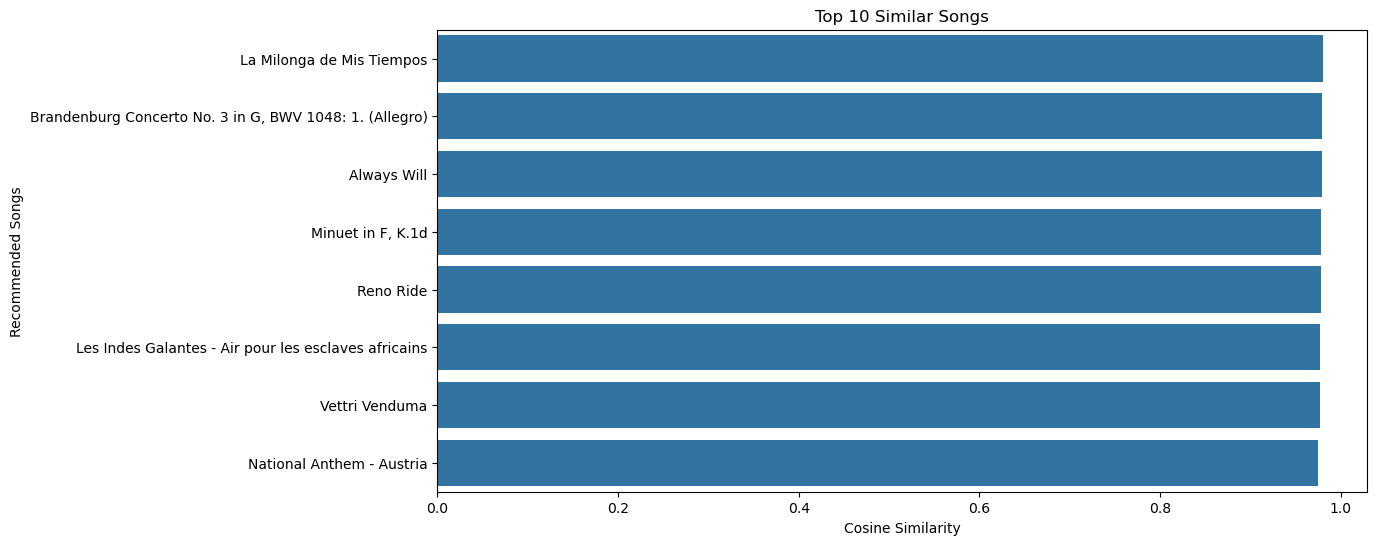

In [55]:
result = recommend_songs("Shape of You", top_n=10)

if isinstance(result, pd.DataFrame):

    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=result,
        x='similarity_score',
        y='track_name'
    )

    plt.title("Top 10 Similar Songs")
    plt.xlabel("Cosine Similarity")
    plt.ylabel("Recommended Songs")

    plt.show()

In [60]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

from sklearn.metrics import pairwise_distances

In [64]:
# Check whether cleaned dataset exists

print("Dataset Shape:", df_clean.shape)

display(df_clean.head())

Dataset Shape: (114000, 21)


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [65]:
audio_features = [
    'danceability',
    'energy',
    'valence',
    'acousticness',
    'instrumentalness',
    'tempo',
    'loudness'
]

X = df_clean[audio_features].copy()

print("Feature Matrix:", X.shape)

Feature Matrix: (114000, 7)


In [66]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled Shape:", X_scaled.shape)

Scaled Shape: (114000, 7)


In [67]:
from sklearn.neighbors import NearestNeighbors

knn_model = NearestNeighbors(
    n_neighbors=11,
    metric='cosine',
    algorithm='brute'
)

knn_model.fit(X_scaled)

print("KNN Model Trained Successfully!")

KNN Model Trained Successfully!


In [68]:
distances, indices = knn_model.kneighbors(
    X_scaled[0].reshape(1, -1)
)

print("Nearest Song Indices:")
print(indices)

print("Cosine Distances:")
print(distances)

Nearest Song Indices:
[[102151      0  62102  99152   5688  21975 100145  17026 111753  70954
   21802]]
Cosine Distances:
[[0.         0.         0.         0.         0.00902375 0.0141062
  0.01544287 0.01758663 0.02571453 0.02632987 0.02680113]]


In [69]:
import numpy as np

def recommend_songs(song_name, top_n=10):

    matches = np.where(
        df_clean['track_name'].str.lower().values
        == song_name.lower()
    )[0]

    if len(matches) == 0:
        return "Song not found!"

    song_index = matches[0]

    distances, indices = knn_model.kneighbors(
        X_scaled[song_index].reshape(1, -1),
        n_neighbors=top_n + 1
    )

    recommended_indices = indices.flatten()[1:]

    similarity_scores = 1 - distances.flatten()[1:]

    recommendations = df_clean.iloc[
        recommended_indices
    ][['track_name', 'artists', 'track_genre']].copy()

    recommendations['similarity_score'] = similarity_scores

    return recommendations.reset_index(drop=True)

In [70]:
recommend_songs("Shape of You", top_n=10)

,track_name,artists,track_genre,similarity_score
0,La Milonga de Mis Tiempos,Francisco Canaro,tango,0.981485
1,"Brandenburg Concerto No. 3 in G, BWV 1048: 1. ...",Johann Sebastian Bach;Berliner Philharmoniker;...,classical,0.980360
2,"Brandenburg Concerto No. 3 in G, BWV 1048: 1. ...",Johann Sebastian Bach;Berliner Philharmoniker;...,german,0.980360
3,"Brandenburg Concerto No. 3 in G, BWV 1048: 1. ...",Johann Sebastian Bach;Berliner Philharmoniker;...,classical,0.980360
4,"Brandenburg Concerto No. 3 in G, BWV 1048: 1. ...",Johann Sebastian Bach;Berliner Philharmoniker;...,classical,0.980360
5,"Brandenburg Concerto No. 3 in G, BWV 1048: 1. ...",Johann Sebastian Bach;Berliner Philharmoniker;...,german,0.980360
6,"Brandenburg Concerto No. 3 in G, BWV 1048: 1. ...",Johann Sebastian Bach;Berliner Philharmoniker;...,german,0.980360
7,Always Will,Steve Martin;Steep Canyon Rangers,bluegrass,0.980151
8,Reno Ride,Clarence White,bluegrass,0.979856
9,"Minuet in F, K.1d",Wolfgang Amadeus Mozart;Erik Smith,classical,0.979715


In [71]:
import os
import joblib

os.makedirs("models", exist_ok=True)
os.makedirs("dataset", exist_ok=True)

df_clean.to_csv(
    "dataset/spotify_cleaned.csv",
    index=False
)

joblib.dump(scaler, "models/scaler.pkl")
joblib.dump(knn_model, "models/knn_model.pkl")

print("Dataset and KNN model saved successfully!")

Dataset and KNN model saved successfully!


In [72]:
from sklearn.neighbors import NearestNeighbors
import time

k_values = [5, 10, 15, 20, 30]

for k in k_values:

    model = NearestNeighbors(
        n_neighbors=k + 1,
        metric='cosine',
        algorithm='brute'
    )

    start_time = time.time()

    model.fit(X_scaled)

    distances, indices = model.kneighbors(
        X_scaled[0].reshape(1, -1)
    )

    execution_time = time.time() - start_time

    print("K:", k)
    print("Execution Time:", round(execution_time, 4))
    print("Average Distance:", round(distances[0][1:].mean(), 4))
    print("-----------------------")

K: 5
Execution Time: 0.0394
Average Distance: 0.0046
-----------------------
K: 10
Execution Time: 0.0397
Average Distance: 0.0135
-----------------------
K: 15
Execution Time: 0.0346
Average Distance: 0.0201
-----------------------
K: 20
Execution Time: 0.0339
Average Distance: 0.0246
-----------------------
K: 30
Execution Time: 0.0329
Average Distance: 0.0306
-----------------------


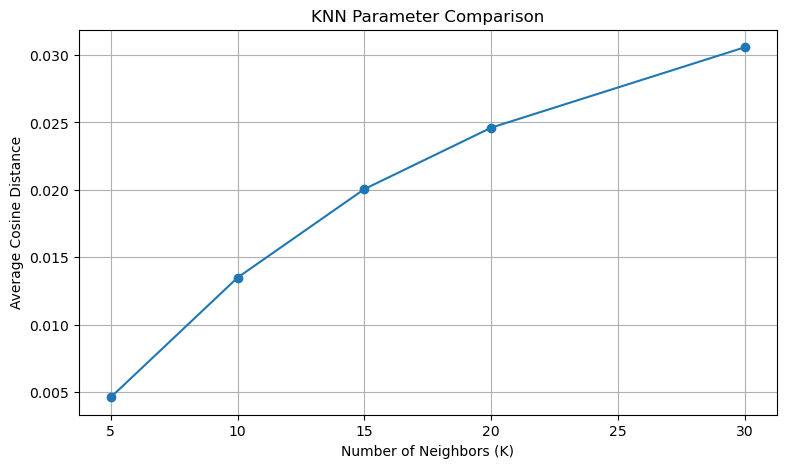

In [73]:
import matplotlib.pyplot as plt

k_values = [5, 10, 15, 20, 30]
avg_distances = []

for k in k_values:

    model = NearestNeighbors(
        n_neighbors=k + 1,
        metric='cosine',
        algorithm='brute'
    )

    model.fit(X_scaled)

    distances, indices = model.kneighbors(
        X_scaled[0].reshape(1, -1)
    )

    avg_distances.append(
        distances[0][1:].mean()
    )

plt.figure(figsize=(9, 5))

plt.plot(k_values, avg_distances, marker='o')

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Average Cosine Distance")
plt.title("KNN Parameter Comparison")

plt.grid()
plt.show()

In [74]:
result = recommend_songs("Shape of You", top_n=10)

if isinstance(result, pd.DataFrame):

    unique_artists = result['artists'].nunique()

    diversity = unique_artists / len(result)

    print("Total Recommendations:", len(result))
    print("Unique Artists:", unique_artists)
    print("Artist Diversity:", round(diversity, 3))

Total Recommendations: 10
Unique Artists: 5
Artist Diversity: 0.5


In [75]:
import time

start_time = time.perf_counter()

result = recommend_songs("Shape of You", top_n=10)

end_time = time.perf_counter()

print(
    "Recommendation Time:",
    round(end_time - start_time, 4),
    "seconds"
)

Recommendation Time: 0.1086 seconds


In [76]:
import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(knn_model, "models/knn_model.pkl")
joblib.dump(scaler, "models/scaler.pkl")

joblib.dump(audio_features, "models/audio_features.pkl")

print("KNN model saved successfully!")

KNN model saved successfully!


In [77]:
!pip install streamlit

In [78]:
!pip install joblib

In [79]:
import os
import joblib

os.makedirs("dataset", exist_ok=True)
os.makedirs("models", exist_ok=True)

df_clean.to_csv(
    "dataset.csv",
    index=False
)

joblib.dump(knn_model, "models/knn_model.pkl")
joblib.dump(scaler, "models/scaler.pkl")
joblib.dump(audio_features, "models/audio_features.pkl")

print("Project files saved!")

Project files saved!


In [80]:
%%writefile app.py

import streamlit as st
import pandas as pd
import numpy as np
import joblib

# Page configuration
st.set_page_config(
    page_title="Spotify Music Recommender",
    page_icon="🎵",
    layout="wide"
)

# Load saved files
df = pd.read_csv("dataset/spotify_cleaned.csv")

knn_model = joblib.load("models/knn_model.pkl")
scaler = joblib.load("models/scaler.pkl")

audio_features = joblib.load("models/audio_features.pkl")

# Prepare features in exactly the same row order
X = df[audio_features].copy()
X_scaled = scaler.transform(X)

# Application title
st.title("🎵 Spotify Music Recommendation System")

st.write(
    "Discover songs similar to your favourite music "
    "using Machine Learning."
)

# Song selection
song_name = st.selectbox(
    "Select Your Favourite Song",
    sorted(df["track_name"].dropna().unique())
)

# Number of recommendations
top_n = st.slider(
    "Number of Recommendations",
    min_value=5,
    max_value=20,
    value=10
)

# Recommendation function
def recommend_songs(song_name, top_n):

    matches = np.where(
        df["track_name"].str.lower().values
        == song_name.lower()
    )[0]

    if len(matches) == 0:
        return pd.DataFrame()

    song_index = matches[0]

    distances, indices = knn_model.kneighbors(
        X_scaled[song_index].reshape(1, -1),
        n_neighbors=top_n + 1
    )

    recommended_indices = indices.flatten()[1:]

    scores = 1 - distances.flatten()[1:]

    result = df.iloc[recommended_indices][
        ["track_name", "artists", "track_genre"]
    ].copy()

    result["Similarity Score"] = scores

    return result.reset_index(drop=True)


# Recommendation button
if st.button("Recommend Songs"):

    recommendations = recommend_songs(
        song_name,
        top_n
    )

    st.subheader("Recommended Songs")

    if recommendations.empty:
        st.warning("No recommendations found.")

    else:
        st.dataframe(
            recommendations,
            use_container_width=True
        )

        st.success("Recommendations generated successfully!")

Writing app.py


In [1]:
import os

print(os.getcwd())

C:\Users\LOKI\Spotify_Music_Recommendation


In [2]:
!pip install streamlit

In [3]:
import os

print(os.getcwd())

C:\Users\LOKI\Spotify_Music_Recommendation
